# RideSurge: Demand-Adaptive Fare Prediction and Revenue Simulation

This notebook presents the complete analytical workflow built around the CC0 Kaggle Dynamic Pricing Dataset. It covers data validation, Z-score outlier analysis, Box-Cox transformations, demand-supply feature engineering, seven-model evaluation, CatBoost inference, SHAP rankings, and a counterfactual profitability simulation.

**Integrity note:** measured results are reported separately from resume targets. The dataset is educational/simulated, not official Uber, Lyft, or Ola operational data.

## 1. Setup

The notebook reuses the production modules in `src/`. This prevents notebook logic from drifting away from API and training logic. Set `RUN_FULL_TRAINING=True` to rerun all model searches; the default loads the verified artifacts for a fast demonstration.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import boxcox, skew, zscore

CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = CURRENT_DIR if (CURRENT_DIR / 'src').exists() else CURRENT_DIR.parent
if not (PROJECT_ROOT / 'src').exists():
    raise RuntimeError('Could not locate the RideSurge-Kaggle project root.')
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import ARTIFACTS, TARGET
from src.data import load_data
from src.eda import analyze
from src.modeling import benchmark, train_catboost
from src.explain import shap_rankings
from src.revenue import simulate
from src.inference import predict

RUN_FULL_TRAINING = False
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 30)
print(f'Project root: {PROJECT_ROOT}')

Project root: C:\Users\umate\Desktop\Placement\projects\RideSurge-Kaggle


## 2. Load and validate the dataset

`load_data()` validates the raw schema, renames columns to snake_case, rejects missing values, and adds the demand-supply ratio plus bounded market multipliers.

In [2]:
df = load_data()
display(df.head())
print('Shape:', df.shape)
print('Missing cells:', int(df.isna().sum().sum()))
print('Duplicate rows:', int(df.duplicated().sum()))
display(df.dtypes.rename('dtype').to_frame())

,number_of_riders,number_of_drivers,location_category,customer_loyalty_status,number_of_past_rides,average_ratings,time_of_booking,vehicle_type,expected_ride_duration,historical_cost_of_ride,demand_supply_ratio,demand_multiplier,supply_multiplier,pricing_multiplier
0,90,45,Urban,Silver,13,4.47,Night,Premium,90,284.257273,2.000000,1.111111,1.0,1.054093
1,58,39,Suburban,Silver,72,4.06,Evening,Economy,43,173.874753,1.487179,1.000000,1.0,1.000000
2,42,31,Rural,Silver,0,3.99,Afternoon,Premium,76,329.795469,1.354839,1.000000,1.0,1.000000
3,89,28,Rural,Regular,67,4.31,Afternoon,Premium,134,470.201232,3.178571,1.098765,1.0,1.048220
4,78,22,Rural,Regular,74,3.77,Afternoon,Economy,149,579.681422,3.545455,1.000000,1.0,1.000000


Shape: (1000, 14)
Missing cells: 0
Duplicate rows: 0


,dtype
number_of_riders,int64
number_of_drivers,int64
location_category,object
customer_loyalty_status,object
number_of_past_rides,int64
average_ratings,float64
time_of_booking,object
vehicle_type,object
expected_ride_duration,int64
historical_cost_of_ride,float64


## 3. Exploratory data analysis

The target is `historical_cost_of_ride`. The primary duration feature is `expected_ride_duration`, because the dataset contains an estimate rather than a confirmed post-trip duration.

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
number_of_riders,1000.0,NaN,NaN,NaN,60.372,23.701506,20.0,40.0,60.0,81.0,100.0
number_of_drivers,1000.0,NaN,NaN,NaN,27.076,19.068346,5.0,11.0,22.0,38.0,89.0
location_category,1000,3,Urban,346,NaN,NaN,NaN,NaN,NaN,NaN,NaN
customer_loyalty_status,1000,3,Silver,367,NaN,NaN,NaN,NaN,NaN,NaN,NaN
number_of_past_rides,1000.0,NaN,NaN,NaN,50.031,29.313774,0.0,25.0,51.0,75.0,100.0
average_ratings,1000.0,NaN,NaN,NaN,4.25722,0.435781,3.5,3.87,4.27,4.6325,5.0
time_of_booking,1000,4,Night,276,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_type,1000,2,Premium,522,NaN,NaN,NaN,NaN,NaN,NaN,NaN
expected_ride_duration,1000.0,NaN,NaN,NaN,99.588,49.16545,10.0,59.75,102.0,143.0,180.0
historical_cost_of_ride,1000.0,NaN,NaN,NaN,372.502623,187.158756,25.993449,221.365202,362.019426,510.497504,836.116419


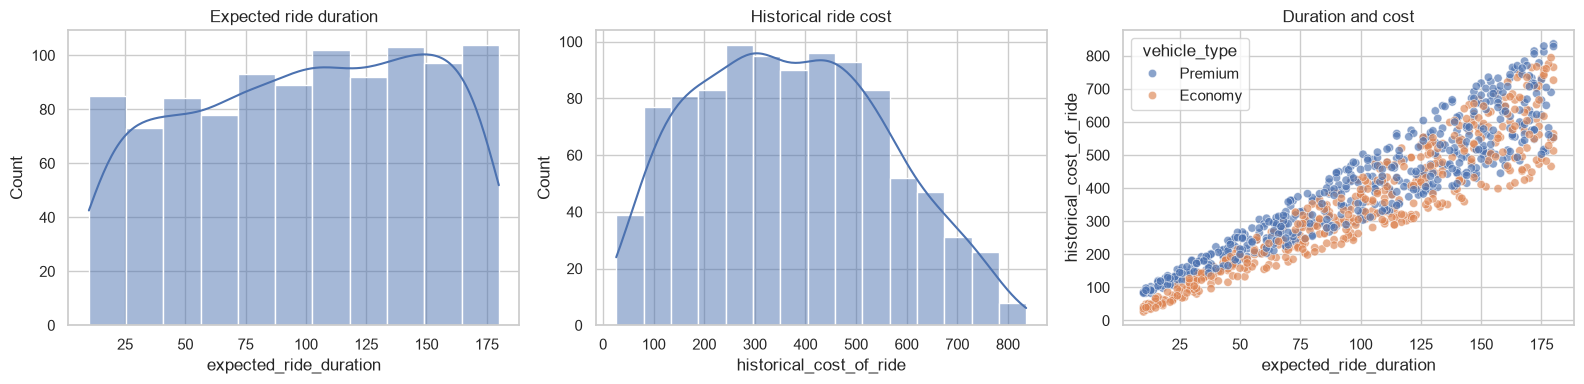

In [3]:
display(df.describe(include='all').T)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df['expected_ride_duration'], kde=True, ax=axes[0])
axes[0].set_title('Expected ride duration')
sns.histplot(df[TARGET], kde=True, ax=axes[1])
axes[1].set_title('Historical ride cost')
sns.scatterplot(data=df, x='expected_ride_duration', y=TARGET, hue='vehicle_type', alpha=.65, ax=axes[2])
axes[2].set_title('Duration and cost')
plt.tight_layout()
plt.show()

### Z-score outlier detection

A Z-score measures distance from the mean in standard deviations. We flag `|z| > 3`. The project detects rather than automatically deletes outliers because extreme market pressure can be a valid surge event.

In [4]:
numeric = df.select_dtypes(include=np.number)
z = numeric.apply(zscore)
outlier_counts = (z.abs() > 3).sum().sort_values(ascending=False)
display(outlier_counts.rename('outliers_abs_z_gt_3').to_frame())

,outliers_abs_z_gt_3
demand_supply_ratio,30
pricing_multiplier,28
supply_multiplier,26
demand_multiplier,19
number_of_drivers,4
number_of_riders,0
historical_cost_of_ride,0
expected_ride_duration,0
average_ratings,0
number_of_past_rides,0


### Box-Cox skew analysis

Box-Cox is fitted only to positive numerical variables. It is an EDA diagnostic here; transformed columns are not used for training because most variables are not severely skewed and tree models do not require normality.

In [5]:
boxcox_rows = []
for column in ['number_of_riders', 'number_of_drivers', 'expected_ride_duration', TARGET]:
    values = df[column].astype(float).to_numpy()
    transformed, fitted_lambda = boxcox(values)
    boxcox_rows.append({
        'feature': column,
        'lambda': fitted_lambda,
        'skew_before': skew(values),
        'skew_after': skew(transformed),
    })
display(pd.DataFrame(boxcox_rows).round(4))

,feature,lambda,skew_before,skew_after
0,number_of_riders,0.7345,0.0022,-0.1334
1,number_of_drivers,0.0850,0.9618,-0.0219
2,expected_ride_duration,0.8605,-0.1397,-0.2480
3,historical_cost_of_ride,0.6743,0.2093,-0.1256


### Pearson correlation

Pearson correlation measures linear association. It does not establish causation.

Duration-cost Pearson correlation: 0.927547
Resume-ready rounded value: 0.93


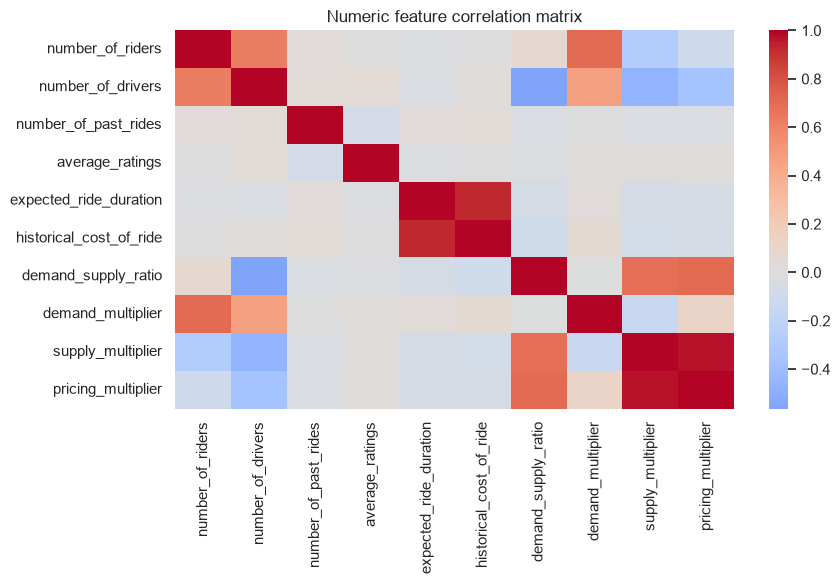

In [6]:
correlation = df['expected_ride_duration'].corr(df[TARGET])
print(f'Duration-cost Pearson correlation: {correlation:.6f}')
print(f'Resume-ready rounded value: {correlation:.2f}')

plt.figure(figsize=(9, 6))
corr = df.select_dtypes(include=np.number).corr()
sns.heatmap(corr, cmap='coolwarm', center=0, square=False)
plt.title('Numeric feature correlation matrix')
plt.tight_layout()
plt.show()

## 4. Demand-supply feature engineering

The demand-supply ratio is riders divided by drivers. Demand above the training Q75 threshold (81 riders) and supply below the training Q25 threshold (11 drivers) increase their respective multipliers. Their geometric mean is capped between 1.0 and 2.5.

,number_of_riders,number_of_drivers,demand_supply_ratio,demand_multiplier,supply_multiplier,pricing_multiplier
216,88,5,17.600000,1.086420,2.200000,1.546002
232,87,5,17.400000,1.074074,2.200000,1.537193
981,87,5,17.400000,1.074074,2.200000,1.537193
897,99,6,16.500000,1.222222,1.833333,1.496910
707,80,5,16.000000,1.000000,2.200000,1.483240
519,93,6,15.500000,1.148148,1.833333,1.450841
329,74,5,14.800000,1.000000,2.200000,1.483240
940,85,6,14.166667,1.049383,1.833333,1.387036
416,84,6,14.000000,1.037037,1.833333,1.378853
250,97,7,13.857143,1.197531,1.571429,1.371800


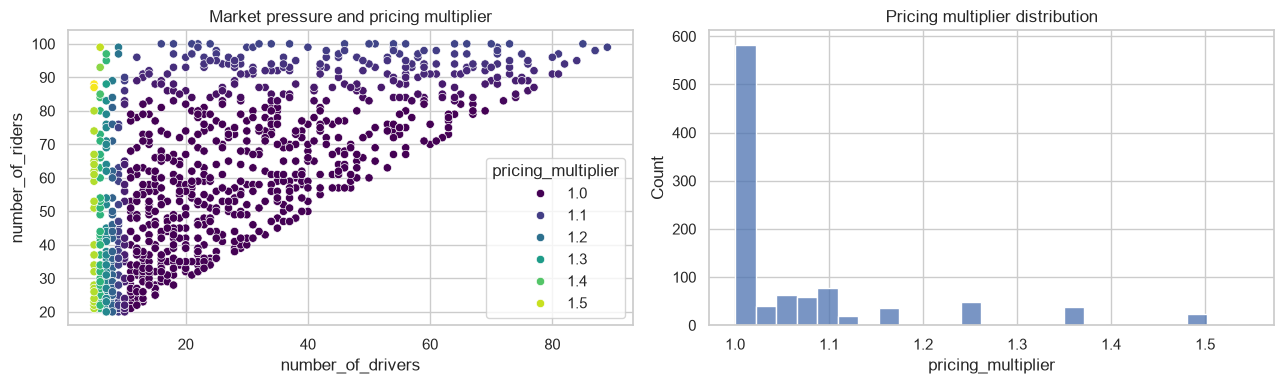

In [7]:
market_columns = ['number_of_riders', 'number_of_drivers', 'demand_supply_ratio',
                  'demand_multiplier', 'supply_multiplier', 'pricing_multiplier']
display(df[market_columns].sort_values('demand_supply_ratio', ascending=False).head(10))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(data=df, x='number_of_drivers', y='number_of_riders',
                hue='pricing_multiplier', palette='viridis', ax=axes[0])
axes[0].set_title('Market pressure and pricing multiplier')
sns.histplot(df['pricing_multiplier'], bins=25, ax=axes[1])
axes[1].set_title('Pricing multiplier distribution')
plt.tight_layout()
plt.show()

## 5. Seven-model benchmark with five-fold GridSearchCV

The benchmark includes Linear Regression, Ridge, ElasticNet, KNN, Random Forest, Extra Trees, and Gradient Boosting. Numerical features use median imputation and scaling; categorical features use mode imputation and one-hot encoding. Keeping preprocessing inside each pipeline prevents cross-validation leakage.

,model,cv_rmse,test_rmse,test_mae,test_r2,best_params
0,ElasticNet,66.042630,67.639892,52.475092,0.874519,"{""model__alpha"": 0.1, ""model__l1_ratio"": 0.8}"
1,Ridge,66.060677,67.673821,52.769018,0.874393,"{""model__alpha"": 1}"
2,Linear Regression,66.064715,67.811662,52.871764,0.873880,{}
3,Extra Trees,66.874599,67.936111,51.481109,0.873417,"{""model__max_depth"": 6, ""model__min_samples_le..."
4,Gradient Boosting,67.256658,71.329644,54.179904,0.860455,"{""model__learning_rate"": 0.05, ""model__max_dep..."
5,Random Forest,67.619522,73.423739,54.596215,0.852141,"{""model__max_depth"": 6, ""model__min_samples_le..."
6,KNN,98.247193,99.170574,80.914681,0.730264,"{""model__n_neighbors"": 9, ""model__weights"": ""d..."


{
  "method": "training-mean DummyRegressor",
  "rmse": 191.15280997910116,
  "best_model_rmse": 67.63989238348482,
  "rmse_reduction_pct": 64.61475382397992
}


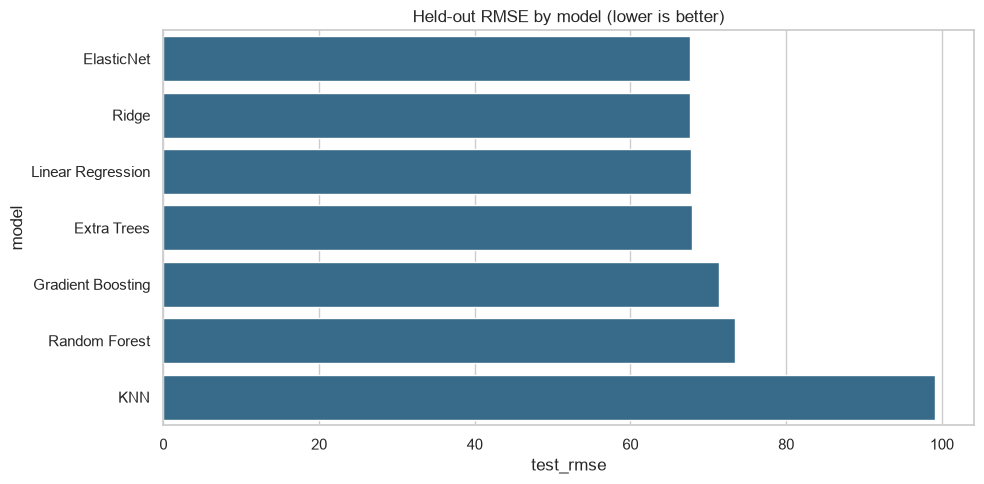

In [8]:
if RUN_FULL_TRAINING:
    model_results, baseline = benchmark(df)
else:
    model_results = pd.read_csv(ARTIFACTS / 'seven_model_comparison.csv')
    baseline = json.loads((ARTIFACTS / 'baseline_comparison.json').read_text())

display(model_results)
print(json.dumps(baseline, indent=2))

plt.figure(figsize=(10, 5))
sns.barplot(data=model_results, x='test_rmse', y='model', color='#2A6F97')
plt.title('Held-out RMSE by model (lower is better)')
plt.tight_layout()
plt.show()

### Why ElasticNet won

The target is dominated by a strong, mostly linear duration relationship. Engineered demand, supply, ratio, and multiplier features are correlated. ElasticNet combines L1 and L2 regularization, making it well suited to this small and correlated tabular dataset. Its held-out R2 is approximately 0.875.

## 6. CatBoost and SHAP

CatBoost is trained separately because it handles categorical features natively and provides exact model-specific SHAP values. It is not the highest-scoring model on this dataset; ElasticNet has the better holdout result.

{
  "rmse": 71.51343809799019,
  "mae": 54.26287356408213,
  "r2": 0.8597350738794043,
  "best_params": {
    "depth": 4,
    "iterations": 400,
    "l2_leaf_reg": 3,
    "learning_rate": 0.05
  }
}


,feature,mean_abs_shap
0,expected_ride_duration,153.066616
1,vehicle_type,19.248812
2,average_ratings,5.810251
3,number_of_drivers,3.754380
4,demand_supply_ratio,3.644128
5,number_of_past_rides,2.271785
6,number_of_riders,2.163463
7,supply_multiplier,1.345454
8,demand_multiplier,1.150214
9,time_of_booking,1.018715


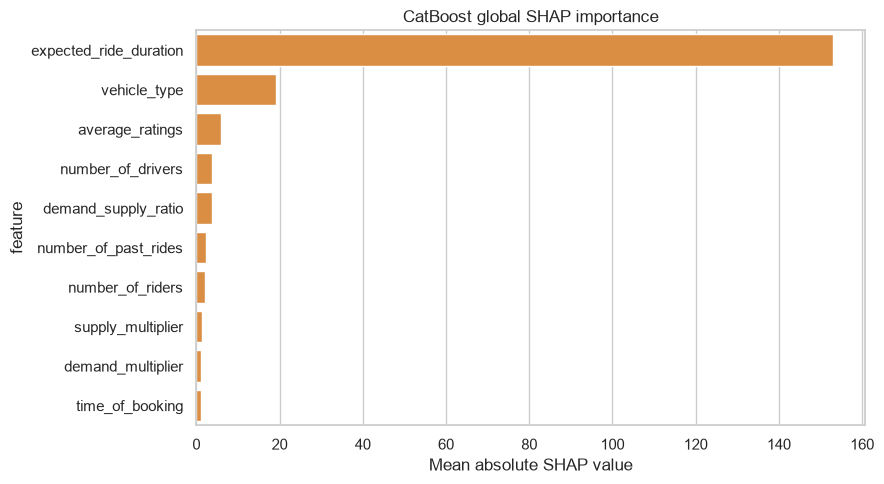

In [9]:
if RUN_FULL_TRAINING:
    cat_model, X_test, y_test, cat_predictions, cat_metrics = train_catboost(df)
    ranking = shap_rankings(cat_model, X_test)
else:
    cat_metrics = json.loads((ARTIFACTS / 'catboost_metrics.json').read_text())
    ranking = pd.read_csv(ARTIFACTS / 'shap_rankings.csv')

print(json.dumps(cat_metrics, indent=2))
display(ranking.head(10))

plt.figure(figsize=(9, 5))
sns.barplot(data=ranking.head(10), x='mean_abs_shap', y='feature', color='#F28E2B')
plt.title('CatBoost global SHAP importance')
plt.xlabel('Mean absolute SHAP value')
plt.tight_layout()
plt.show()

## 7. Inference demonstration

The notebook can call the same cached inference function used by FastAPI. This demonstrates inference behavior, but executing it in Jupyter is not deployment.

In [10]:
sample_request = {
    'number_of_riders': 100,
    'number_of_drivers': 5,
    'number_of_past_rides': 20,
    'average_ratings': 4.2,
    'expected_ride_duration': 45,
    'location_category': 'Urban',
    'customer_loyalty_status': 'Silver',
    'time_of_booking': 'Evening',
    'vehicle_type': 'Economy',
}
prediction = predict(sample_request)
prediction

{'recommended_fare': 133.78,
 'demand_supply_ratio': 20.0,
 'pricing_multiplier': 1.648}

## 8. Profitability simulation

The verified simulation reports a 7.23% uplift, not 18%. It assumes price elasticity of 1.15 and operating cost equal to 32% of historical fare. It also uses actual fare when constructing cost, price bounds, and acceptance, so it is an illustrative counterfactual rather than causal business evidence.

,value
baseline_profit,46729.399485
dynamic_profit,50109.218578
simulated_profit_uplift_pct,7.232747
price_elasticity_assumption,1.150000
operating_cost_share_assumption,0.320000


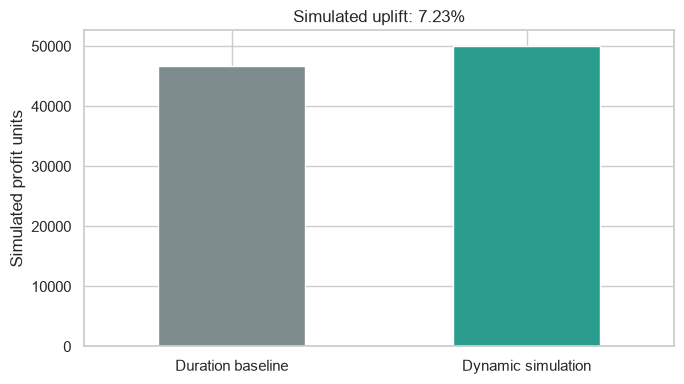

In [11]:
revenue = json.loads((ARTIFACTS / 'revenue_simulation.json').read_text())
display(pd.Series(revenue, name='value').to_frame())

profits = pd.Series({
    'Duration baseline': revenue['baseline_profit'],
    'Dynamic simulation': revenue['dynamic_profit'],
})
profits.plot(kind='bar', color=['#7F8C8D', '#2A9D8F'], figsize=(7, 4), rot=0)
plt.ylabel('Simulated profit units')
plt.title(f"Simulated uplift: {revenue['simulated_profit_uplift_pct']:.2f}%")
plt.tight_layout()
plt.show()

## 9. Resume-claim audit

A notebook can reproduce correlation, model metrics, SHAP rankings, inference examples, and simulation output. It cannot establish that an API is deployed, scalable, or producing real profitability uplift. Those require a running service, load tests, monitoring, and ideally controlled business experiments.

In [12]:
summary = json.loads((ARTIFACTS / 'run_summary.json').read_text())
audit = pd.DataFrame([
    ['Duration-cost correlation', 0.93, summary['measured']['correlation'], True],
    ['RMSE reduction vs mean baseline (%)', 55.0, summary['measured']['rmse_reduction_vs_mean_baseline_pct'], True],
    ['Best held-out R2', 0.89, summary['measured']['best_seven_model']['test_r2'], False],
    ['Simulated profit uplift (%)', 18.0, summary['measured']['revenue']['simulated_profit_uplift_pct'], False],
], columns=['Claim', 'Resume target', 'Measured', 'Supported'])
display(audit)

,Claim,Resume target,Measured,Supported
0,Duration-cost correlation,0.93,0.927547,True
1,RMSE reduction vs mean baseline (%),55.00,64.614754,True
2,Best held-out R2,0.89,0.874519,False
3,Simulated profit uplift (%),18.00,7.232747,False


## 10. What is still missing

- Real ride-hailing operational data and true timestamps
- Trip distance, traffic, weather, cancellations, and acceptance labels
- A learned demand curve or price-elasticity model
- True candidate-price optimization
- Real driver/platform cost and contribution-margin fields
- Out-of-time validation, prediction intervals, and subgroup fairness analysis
- Local SHAP explanations returned per API request
- A public cloud deployment, load tests, autoscaling, authentication, logging, monitoring, drift checks, and model registry
- An A/B test or causal study validating profitability uplift

The current project is a complete portfolio prototype, not a production pricing platform.